# Thermal Model Comparison: Baseline vs. Balanced Joint Training

This read-only notebook compares saved, held-out evaluation artifacts for the Dataset 2-only baseline and the balanced Dataset 1 + Dataset 2 model. It does not load model weights, run inference, train, or modify source data.

**Read this notebook for the final comparison:** localization quality, the locked operating thresholds, and the recall-versus-bird-false-positive tradeoff on Dataset 2.

The analysis centers Dataset 2 because it is the only source with bird hard negatives. It separates **detection quality** (mAP and object-level metrics) from the image-level drone-present decision rule.

## Interpretation guardrails

- The Dataset 2-only baseline selected its operating threshold (`0.25`) on Dataset 2 validation data.
- The balanced combined model selected its operating threshold (`0.50`) on Dataset 2 validation data.
- Comparisons at each model's selected threshold describe their pre-specified operating behavior.
- The combined model at `0.25` is a **held-out sensitivity analysis**, calculated after test evaluation to illustrate the recall/false-positive tradeoff. It must not be presented as a post-test-optimized operating threshold.
- A higher rate of bird detections after combined training is consistent with Dataset 1 adding many drone-positive examples but no bird hard negatives. This is a plausible mechanism, not a causal conclusion established by one experiment.

In [1]:
from __future__ import annotations

from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

WORKING_DIRECTORY = Path.cwd().resolve()
if (WORKING_DIRECTORY / '.git').is_dir():
    REPO_ROOT = WORKING_DIRECTORY
elif (WORKING_DIRECTORY.parent / '.git').is_dir():
    REPO_ROOT = WORKING_DIRECTORY.parent
else:
    raise RuntimeError('Open this notebook from the repository root or notebooks/ directory.')

EVALUATION_ROOT = REPO_ROOT / 'results' / 'thermal-ir' / 'evaluation'
BASELINE_ROOT = EVALUATION_ROOT / 'experiment_a_dataset2_only_batch32'
COMBINED_ROOT = EVALUATION_ROOT / 'experiment_e_combined_balanced_yolo26n_batch32' / 'dataset2_test'
ANALYSIS_ROOT = REPO_ROOT / 'results' / 'thermal-ir' / 'analysis' / 'dataset2_only_vs_combined'
ANALYSIS_ROOT.mkdir(parents=True, exist_ok=True)

required = [
    BASELINE_ROOT / 'test_detection_metrics.json',
    BASELINE_ROOT / 'test_decision_metrics.json',
    BASELINE_ROOT / 'test_image_decisions.csv',
    COMBINED_ROOT / 'test_detection_metrics.json',
    COMBINED_ROOT / 'test_decision_metrics.json',
    COMBINED_ROOT / 'test_image_scores.csv',
]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError('Saved evaluation artifacts are missing: ' + ', '.join(missing))


## Load the saved held-out results

The Dataset 2 test set contains 1,878 drone-present images and 753 bird hard-negative images in both comparisons.

In [2]:
baseline_detection = json.loads((BASELINE_ROOT / 'test_detection_metrics.json').read_text(encoding='utf-8'))
combined_detection = json.loads((COMBINED_ROOT / 'test_detection_metrics.json').read_text(encoding='utf-8'))
baseline_selected = json.loads((BASELINE_ROOT / 'test_decision_metrics.json').read_text(encoding='utf-8'))
combined_selected = json.loads((COMBINED_ROOT / 'test_decision_metrics.json').read_text(encoding='utf-8'))

baseline_scores = pd.read_csv(BASELINE_ROOT / 'test_image_decisions.csv')
combined_scores = pd.read_csv(COMBINED_ROOT / 'test_image_scores.csv')
for scores in (baseline_scores, combined_scores):
    scores['ground_truth_drone_present'] = scores.ground_truth_drone_present.astype(str).str.lower().eq('true')

for name, scores in {'Dataset 2-only': baseline_scores, 'Balanced combined': combined_scores}.items():
    positives = int(scores.ground_truth_drone_present.sum())
    birds = int(scores.export_policy.eq('negative_bird').sum())
    if (positives, birds) != (1878, 753):
        raise RuntimeError(f'{name} has unexpected Dataset 2 test composition: {positives} drone, {birds} bird images.')
print('Both saved score files describe the same 1,878 drone and 753 bird Dataset 2 test images.')


Both saved score files describe the same 1,878 drone and 753 bird Dataset 2 test images.


## Compare detection quality

mAP evaluates detection boxes across confidence thresholds and overlap requirements. It is not the same as the final yes/no image decision rule.

,precision,recall,mAP@0.5,mAP@0.5:0.95
model,,,,
Dataset 2-only,87.46%,87.54%,87.95%,39.55%
Balanced combined,88.96%,89.03%,87.83%,40.12%


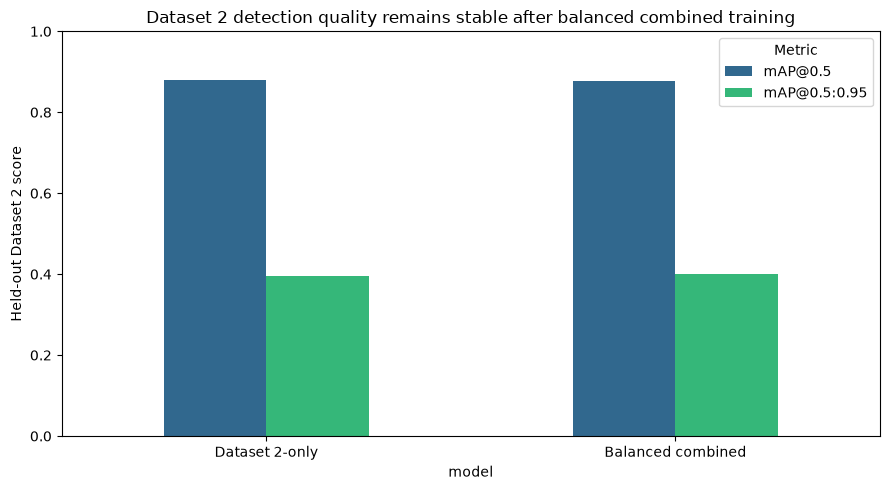

In [3]:
detection_comparison = pd.DataFrame([
    {'model': 'Dataset 2-only', 'precision': baseline_detection['metrics/precision(B)'], 'recall': baseline_detection['metrics/recall(B)'], 'mAP@0.5': baseline_detection['metrics/mAP50(B)'], 'mAP@0.5:0.95': baseline_detection['metrics/mAP50-95(B)']},
    {'model': 'Balanced combined', 'precision': combined_detection['metrics/precision(B)'], 'recall': combined_detection['metrics/recall(B)'], 'mAP@0.5': combined_detection['metrics/mAP50(B)'], 'mAP@0.5:0.95': combined_detection['metrics/mAP50-95(B)']},
]).set_index('model')
display(detection_comparison.style.format('{:.2%}'))
detection_comparison.to_csv(ANALYSIS_ROOT / 'dataset2_detection_comparison.csv')

figure, axis = plt.subplots(figsize=(9, 5))
detection_comparison[['mAP@0.5', 'mAP@0.5:0.95']].plot.bar(ax=axis, rot=0, color=['#31688e', '#35b779'])
axis.set_ylim(0, 1); axis.set_ylabel('Held-out Dataset 2 score'); axis.set_title('Dataset 2 detection quality remains stable after balanced combined training')
axis.legend(title='Metric'); figure.tight_layout()
figure.savefig(ANALYSIS_ROOT / 'dataset2_detection_comparison.png', dpi=200)
plt.show()


## Compare the selected operating thresholds

Each model's selected threshold was chosen on Dataset 2 validation data before evaluating this test set. The combined model's higher threshold favors fewer bird false positives at the cost of more missed drone images.

In [4]:
def selected_row(name: str, metrics: dict) -> dict:
    positives = metrics['true_positive'] + metrics['false_negative']
    birds = metrics['false_positive'] + metrics['true_negative']
    return {
        'model': name, 'threshold': metrics['decision_threshold'],
        'drone_true_positive': metrics['true_positive'], 'drone_false_negative': metrics['false_negative'],
        'drone_false_negative_rate': metrics['false_negative'] / positives,
        'bird_false_positive': metrics['false_positive'], 'bird_false_positive_rate': metrics.get('bird_false_positive_rate', metrics.get('overall_false_positive_rate')),
        'image_precision': metrics['precision'], 'image_recall': metrics['recall'], 'image_f1': metrics['f1'],
    }

selected_comparison = pd.DataFrame([
    selected_row('Dataset 2-only', baseline_selected),
    selected_row('Balanced combined', combined_selected),
]).set_index('model')
display(selected_comparison.style.format({'threshold':'{:.2f}', 'drone_false_negative_rate':'{:.2%}', 'bird_false_positive_rate':'{:.2%}', 'image_precision':'{:.2%}', 'image_recall':'{:.2%}', 'image_f1':'{:.2%}'}))
selected_comparison.to_csv(ANALYSIS_ROOT / 'dataset2_selected_threshold_comparison.csv')


,threshold,drone_true_positive,drone_false_negative,drone_false_negative_rate,bird_false_positive,bird_false_positive_rate,image_precision,image_recall,image_f1
model,,,,,,,,,
Dataset 2-only,0.25,1830,48,2.56%,5,0.66%,99.73%,97.44%,98.57%
Balanced combined,0.50,1765,113,6.02%,0,0.00%,100.00%,93.98%,96.90%


## Inspect held-out threshold sensitivity

This recomputes image decisions from saved scores at common thresholds. It does not select a new model or replace the validation-selected operating rule. Its purpose is to show the tradeoff between missed drones and bird false positives.

In particular, compare both models at `0.25`, the original Dataset 2-only operating threshold. The combined model's score calibration may be more drone-positive after exposure to additional Dataset 1 drone examples; that interpretation remains a hypothesis rather than proof of causality.

,threshold,true_positive,false_positive,false_negative,true_negative,false_negative_rate,bird_false_positive_rate,precision,recall,f1,model
7,0.25,1878,12,0,741,0.00%,1.59%,99.37%,100.00%,99.68%,Balanced combined
2,0.25,1830,5,48,748,2.56%,0.66%,99.73%,97.44%,98.57%,Dataset 2-only
8,0.50,1765,0,113,753,6.02%,0.00%,100.00%,93.98%,96.90%,Balanced combined
3,0.50,901,0,977,753,52.02%,0.00%,100.00%,47.98%,64.84%,Dataset 2-only


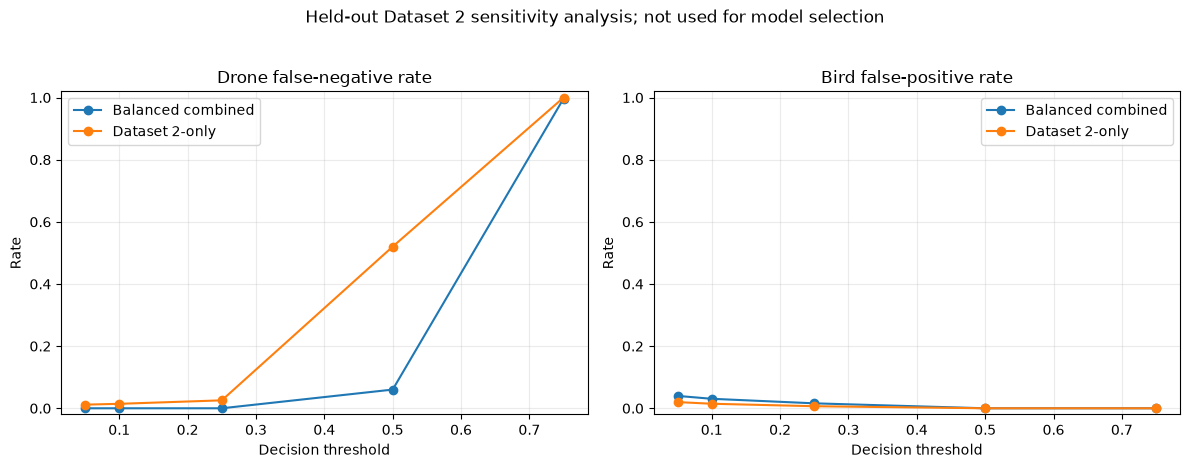

In [5]:
def threshold_summary(scores: pd.DataFrame, threshold: float) -> dict:
    predicted = scores.max_confidence.ge(threshold)
    positive = scores.ground_truth_drone_present
    birds = scores.export_policy.eq('negative_bird')
    tp = int((positive & predicted).sum()); fn = int((positive & ~predicted).sum())
    fp = int((~positive & predicted).sum()); tn = int((~positive & ~predicted).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0; recall = tp / (tp + fn) if tp + fn else 0.0
    return {'threshold': threshold, 'true_positive': tp, 'false_positive': fp, 'false_negative': fn, 'true_negative': tn, 'false_negative_rate': fn / (tp + fn), 'bird_false_positive_rate': float(predicted.loc[birds].mean()), 'precision': precision, 'recall': recall, 'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0}

thresholds = (0.05, 0.10, 0.25, 0.50, 0.75)
sensitivity = pd.concat([
    pd.DataFrame([threshold_summary(baseline_scores, threshold) for threshold in thresholds]).assign(model='Dataset 2-only'),
    pd.DataFrame([threshold_summary(combined_scores, threshold) for threshold in thresholds]).assign(model='Balanced combined'),
]).reset_index(drop=True)
display(sensitivity.loc[sensitivity.threshold.isin([0.25, 0.50])].sort_values(['threshold', 'model']).style.format({'threshold':'{:.2f}', 'false_negative_rate':'{:.2%}', 'bird_false_positive_rate':'{:.2%}', 'precision':'{:.2%}', 'recall':'{:.2%}', 'f1':'{:.2%}'}))
sensitivity.to_csv(ANALYSIS_ROOT / 'dataset2_threshold_sensitivity.csv', index=False)

figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for model, rows in sensitivity.groupby('model'):
    axes[0].plot(rows.threshold, rows.false_negative_rate, marker='o', label=model)
    axes[1].plot(rows.threshold, rows.bird_false_positive_rate, marker='o', label=model)
for axis, title in zip(axes, ['Drone false-negative rate', 'Bird false-positive rate']):
    axis.set_xlabel('Decision threshold'); axis.set_ylabel('Rate'); axis.set_ylim(-0.02, 1.02); axis.set_title(title); axis.grid(alpha=0.25); axis.legend()
figure.suptitle('Held-out Dataset 2 sensitivity analysis; not used for model selection', y=1.03)
figure.tight_layout()
figure.savefig(ANALYSIS_ROOT / 'dataset2_threshold_tradeoff.png', dpi=200, bbox_inches='tight')
plt.show()


## Paper-ready model-analysis findings

1. **Balanced joint training preserved Dataset 2 localization.** Held-out Dataset 2 mAP@0.5 changed from 87.95% for Dataset 2-only to 87.83% for the balanced combined model; mAP@0.5:0.95 rose from 39.55% to 40.12%.

2. **The validation-selected operating points express different tradeoffs.** Dataset 2-only used a 0.25 threshold and had a 2.56% image-level drone false-negative rate with a 0.66% bird false-positive rate. The combined model used a more conservative 0.50 threshold and had a 6.02% false-negative rate with 0.00% bird false positives.

3. **At a common 0.25 threshold, the combined model was more sensitive but less bird-specific.** On the held-out sensitivity analysis, it had 0.00% drone false negatives and a 1.59% bird false-positive rate, compared with 2.56% and 0.66% for Dataset 2-only. This pattern is consistent with added Dataset 1 drone examples shifting confidence toward drone predictions, while Dataset 1 itself contains no bird hard-negative class. It is not proof that class count alone caused the shift.

4. **Scope determines the preferred final model.** Dataset 2-only remains the narrowest evidence-backed choice for a Dataset 2 drone-versus-bird operating setting. The balanced combined model is preferable when the aim is one detector with demonstrated performance across both Dataset 1 and Dataset 2, provided the recall/bird-false-positive tradeoff is explicitly reported.